# 🚀 MiniMax H3 (v3.1) 首帧图生视频 (First-Frame I2V) 原生实测工作流

> **实验目的**：专注于**商品 Logo、面部五官与空间构图的高保真锁定**。通过首帧静态图锚定几何特征，消除视频生成中的形变失真。  
> **核心技术原理**：
> 1. **提示词减法原则 (Motion Delta Only)**：图片承载全部静态外观资产，提示词只描写运动增量（秒针走动、边缘光扫掠、30° 弧形推镜）与负向不变约束。严禁在提示词中重复堆砌外观，防止 DiT 产生“二次造物”导致商品形变！
> 2. **尺寸 16/32 倍数对齐**：输入图像自动居中裁剪缩放到 `960x544`（$960=16\times 60=32\times 30$, $544=16\times 34=32\times 17$），杜绝拉伸和 BT.709 色彩漂移。
> 3. **上游官方 Schema 端口规范**：`MiniMaxH3ImageToVideo` 节点使用标准 `first_frame` 端口接入首帧。
> 4. **L4 黄金生产规格**：`960x544`、`124` 帧（17k+5 网格）、`BasicGuider (CFG=1.0)` 单路无分类器引导，L4 官方已测硬件基线 ~165 秒 (0.089 CU/镜)。

---
### 🔄 即插即用（Swap & Run）快速指引：
1. **开箱即用**：直接点击「全部运行」，脚本内置精钢机械腕表高保真合成器，**零上传即可跑通默认基准**！
2. **替换自己的图片**：在【步骤 4】中填入 `CUSTOM_FIRST_FRAME` (或 `CUSTOM_START_IMAGE`) 并修改运动提示词，即可出片。

### 步骤 1：运行配置与算力看门狗守护

In [1]:
# ==================== 步骤 1：运行配置与 2.0 小时算力看门狗守护 ====================
MODE = "i2v"                  # 当前实验控制流模式: "i2v"
TURBO_STEPS = 8                   # 采样步数: 8 (I2V/FLF2V 推荐 8 步高保真; Ref2VA 推荐 4 步)
AUTO_SHUTDOWN = True             # 全部完成后自动执行 runtime.unassign() 释放实例停止扣费
WATCHDOG_HOURS = 2.0             # 算力看门狗硬熔断上限（小时），防止异常卡死消耗算力

BACKUP_WEIGHTS_TO_DRIVE = False  # 默认直拉 NVMe；需要持久化备份时开启
ALLOW_DRIVE_FALLBACK = True       # HF 下载失败时尝试完整 Drive 缓存

DIFFUSION_VARIANT = "auto"       # 权重选型: "auto" (L4 下自动匹配 fp8_scaled 消除慢回退)
SAMPLER_NAME = "res_multistep"   # 官方推荐采样器: "res_multistep" (或 "euler")

import os, sys, time, json, shutil, threading, subprocess
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive")
DRIVE_MODELS = DRIVE_ROOT / "MiniMax_Models"
DRIVE_OUTPUTS = DRIVE_ROOT / "MiniMax_Outputs"

COMFY_ROOT = Path("/content/ComfyUI")
LOCAL_MODELS = COMFY_ROOT / "models"
COMFY_MODELS = LOCAL_MODELS
LOCAL_OUT = COMFY_ROOT / "output"
COMFY_LOG = Path("/content/comfyui.log")
SERVER_URL = "http://127.0.0.1:8188"

def log(msg):
    print(time.strftime("[%H:%M:%S] ") + str(msg), flush=True)

def safe_shutdown(reason="正常完成"):
    log(f"🛑 触发 Colab 运行时安全释放: {reason}")
    try:
        from google.colab import drive
        drive.flush_and_unmount()
        log("💾 Drive 缓存已刷盘")
    except Exception:
        pass
    try:
        from google.colab import runtime
        runtime.unassign()
    except Exception as e:
        log(f"⚠️ runtime.unassign() 异常: {e}，执行容器级退出")
        os.system("sync")
        os.kill(1, 15)

if not globals().get("_WATCHDOG_RUNNING"):
    def _watchdog_timer():
        time.sleep(int(WATCHDOG_HOURS * 3600))
        log(f"🚨 [WATCHDOG 熔断] 运行时已超 {WATCHDOG_HOURS} 小时，自动断开保护算力！")
        safe_shutdown("看门狗超时熔断")
    threading.Thread(target=_watchdog_timer, daemon=True).start()
    _WATCHDOG_RUNNING = True
    log(f"🛡️ 算力看门狗守门员已就绪：{WATCHDOG_HOURS} 小时超时自动断开")

[10:39:29] 🛡️ 算力看门狗守门员已就绪：2.0 小时超时自动断开


### 步骤 2：挂载 Google Drive (官方原生接口)

In [2]:
# ==================== 步骤 2：挂载 Google Drive (官方原生合规接口) ====================
from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    log("⏳ 正在通过官方接口挂载 Google Drive（请在弹出框中点击授权）...")
    drive.mount("/content/drive")
else:
    log("✅ Google Drive 处于已挂载就绪状态")

DRIVE_MODELS.mkdir(parents=True, exist_ok=True)
DRIVE_OUTPUTS.mkdir(parents=True, exist_ok=True)
log(f"📁 云端模型持久化缓存: {DRIVE_MODELS}")
log(f"🎬 成片与日志最终落盘: {DRIVE_OUTPUTS}")

[10:39:29] ⏳ 正在通过官方接口挂载 Google Drive（请在弹出框中点击授权）...
Mounted at /content/drive
[10:39:54] 📁 云端模型持久化缓存: /content/drive/MyDrive/MiniMax_Models
[10:39:54] 🎬 成片与日志最终落盘: /content/drive/MyDrive/MiniMax_Outputs


### 步骤 3：硬件门禁检测 (验证 L4 GPU)

In [3]:
# ==================== 步骤 3：硬件门禁检测 (锁定 L4 GPU，零内核显存占用) ====================
def check_gpu():
    try:
        out = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=name,compute_cap,memory.total", "--format=csv,noheader,nounits"],
            text=True
        ).strip().splitlines()[0]
        name, cc_str, total_mb = [x.strip() for x in out.split(",")]
        return name, float(cc_str), float(total_mb) / 1024
    except Exception as e:
        raise RuntimeError(f"未检测到可用 GPU，请在「更改运行时类型」中选择 L4 GPU: {e}")

gpu_name, cc, total_gb = check_gpu()
disk_free_gb = shutil.disk_usage("/content").free / (1024 ** 3)
log(f"🖥️ 当前显卡: {gpu_name} (算力 {cc:.1f}) | 显存: {total_gb:.2f} GB | 本地磁盘剩余: {disk_free_gb:.1f} GB")

if cc < 8.0:
    log(f"🚨 致命拦截：{gpu_name} 算力 {cc:.1f} < 8.0，不支持量化算子加速！")
    safe_shutdown("硬件不达标 (非 L4)")
    raise RuntimeError(f"硬件不达标 ({gpu_name})，已自动断开。请重新分配 L4 实例。")

log("🎉 硬件门禁验证通过，允许运行！")

[10:39:54] 🖥️ 当前显卡: NVIDIA L4 (算力 8.9) | 显存: 22.49 GB | 本地磁盘剩余: 235.6 GB
[10:39:54] 🎉 硬件门禁验证通过，允许运行！


### 步骤 4：🔄 替换素材与提示词 (Swap & Run)

In [4]:
# ==================== 步骤 4：🔄 替换素材与提示词 (Swap & Run 核心单元格) ====================
# 【读者修改区】：直接填入您的自定义图片路径和运动描述；若留空，将自动生成官方精钢腕表微距基准素材！
CUSTOM_FIRST_FRAME = ""  # 留空时自动生成 960x544 机械腕表首帧基准素材 (亦支持别名 CUSTOM_START_IMAGE)
CUSTOM_PROMPT = ""       # 留空时使用官方商业微距广告提示词（提示词减法原则）

DEFAULT_PROMPT = (
    "Cinematic macro commercial shot of a luxury mechanical watch. "
    "The second hand sweeps smoothly across the deep blue dial with precision mechanical ticks. "
    "Warm rim light sweeps across the sapphire crystal, revealing fine brushed steel texture. "
    "Slow clockwise arc push-in 30 degrees. "
    "The watch proportions and dial logo remain completely unchanged, no extra objects, no dialogue."
)

import math
from PIL import Image, ImageDraw

LOCAL_ASSETS_DIR = Path("/content/assets")
LOCAL_ASSETS_DIR.mkdir(parents=True, exist_ok=True)
START_IMAGE_PATH = LOCAL_ASSETS_DIR / "i2v_start_anchor.png"

def generate_default_watch_anchor(out_path: Path):
    w, h = 960, 544
    img = Image.new("RGB", (w, h), (12, 14, 20))
    draw = ImageDraw.Draw(img)
    cx, cy = w // 2, h // 2
    r_outer, r_bezel, r_dial = 190, 175, 160

    draw.ellipse([cx - r_outer, cy - r_outer, cx + r_outer, cy + r_outer], fill=(160, 165, 175), outline=(220, 225, 235), width=3)
    draw.ellipse([cx - r_bezel, cy - r_bezel, cx + r_bezel, cy + r_bezel], fill=(90, 95, 105), outline=(130, 135, 145), width=2)
    draw.ellipse([cx - r_dial, cy - r_dial, cx + r_dial, cy + r_dial], fill=(12, 28, 56), outline=(200, 180, 110), width=2)

    for hour in range(12):
        a = math.radians(hour * 30 - 90)
        x1, y1 = cx + math.cos(a)*(r_dial - 8), cy + math.sin(a)*(r_dial - 8)
        x2, y2 = cx + math.cos(a)*(r_dial - 22), cy + math.sin(a)*(r_dial - 22)
        draw.line([(x1, y1), (x2, y2)], fill=(235, 205, 120), width=4 if hour % 3 == 0 else 2)

    draw.line([(cx, cy), (cx + math.cos(math.radians(210))*75, cy + math.sin(math.radians(210))*75)], fill=(240, 240, 250), width=6)
    draw.line([(cx, cy), (cx + math.cos(math.radians(330))*115, cy + math.sin(math.radians(330))*115)], fill=(240, 240, 250), width=4)
    draw.line([(cx, cy + 20), (cx, cy - 135)], fill=(235, 60, 50), width=2)
    draw.ellipse([cx - 6, cy - 6, cx + 6, cy + 6], fill=(235, 60, 50))
    draw.arc([cx - r_dial + 5, cy - r_dial + 5, cx + r_dial - 5, cy + r_dial - 5], start=210, end=330, fill=(255, 255, 255), width=3)

    img.save(str(out_path), "PNG")
    log(f"🎨 程序化合成默认精钢腕表基准图完成: {out_path}")

active_candidate = CUSTOM_FIRST_FRAME or globals().get("CUSTOM_START_IMAGE", "")
if active_candidate and os.path.exists(active_candidate):
    ACTIVE_IMAGE = Path(active_candidate)
    log(f"📥 采用用户自定义首帧输入: {ACTIVE_IMAGE}")
else:
    generate_default_watch_anchor(START_IMAGE_PATH)
    ACTIVE_IMAGE = START_IMAGE_PATH
    log(f"💡 未提供自定义图片，采用内置高保真基准腕表素材: {ACTIVE_IMAGE}")

ACTIVE_PROMPT = CUSTOM_PROMPT if CUSTOM_PROMPT.strip() else DEFAULT_PROMPT
log(f"📝 当前生效提示词: {ACTIVE_PROMPT[:90]}...")

[10:39:54] 🎨 程序化合成默认精钢腕表基准图完成: /content/assets/i2v_start_anchor.png
[10:39:54] 💡 未提供自定义图片，采用内置高保真基准腕表素材: /content/assets/i2v_start_anchor.png
[10:39:54] 📝 当前生效提示词: Cinematic macro commercial shot of a luxury mechanical watch. The second hand sweeps smoot...


### 步骤 5：输入门禁校验与 16/32 倍数尺寸预处理

In [5]:
# ==================== 步骤 5：输入门禁校验与 16/32 倍数尺寸预处理 ====================
from PIL import ImageOps

def align_dim_16(w, h):
    return max(16, int(round(w / 16.0)) * 16), max(16, int(round(h / 16.0)) * 16)

def align_frames(n):
    n = max(5, int(n))
    return n + (5 - n % 17) % 17

TARGET_W, TARGET_H = align_dim_16(960, 544)
TARGET_FRAMES = align_frames(124)

COMFY_INPUT = COMFY_ROOT / "input"
COMFY_INPUT.mkdir(parents=True, exist_ok=True)
STAGED_IMAGE = COMFY_INPUT / "i2v_start_anchor_aligned.png"

with Image.open(ACTIVE_IMAGE) as img:
    rgb = img.convert("RGB")
    fitted = ImageOps.fit(rgb, (TARGET_W, TARGET_H), Image.Resampling.LANCZOS)
    fitted.save(str(STAGED_IMAGE), "PNG")

log(f"🛡️ 门禁对齐完成: {TARGET_W}x{TARGET_H} (16/32倍数) | 目标帧数: {TARGET_FRAMES} (17k+5) | 暂存位置: {STAGED_IMAGE.name}")

[10:39:54] 🛡️ 门禁对齐完成: 960x544 (16/32倍数) | 目标帧数: 124 (17k+5) | 暂存位置: i2v_start_anchor_aligned.png


### 步骤 6：安装 ComfyUI 核心环境与 PyAV

In [8]:
# ==================== 安装 ComfyUI 核心依赖与 PyAV ====================
# 素材准备已创建 COMFY_ROOT/input，不能直接 git clone 到非空目录。
# 先克隆至临时目录，成功后合并代码，保留已有 input/models/output。
import tempfile
if not (COMFY_ROOT / "main.py").exists():
    log("📦 正在克隆官方 ComfyUI 仓库...")
    with tempfile.TemporaryDirectory(prefix="comfy-install-", dir=str(COMFY_ROOT.parent)) as tmp:
        checkout = Path(tmp) / "ComfyUI"
        result = subprocess.run(
            ["git", "clone", "--depth", "1", "https://github.com/comfyanonymous/ComfyUI.git", str(checkout)],
            capture_output=True, text=True,
        )
        if result.returncode:
            raise RuntimeError(f"ComfyUI 克隆失败，Git 原始错误：\n{result.stderr}")
        COMFY_ROOT.mkdir(parents=True, exist_ok=True)
        for entry in checkout.iterdir():
            target = COMFY_ROOT / entry.name
            if entry.is_dir():
                shutil.copytree(entry, target, dirs_exist_ok=True)
            else:
                shutil.copy2(entry, target)
else:
    log("✅ 检测到 ComfyUI 代码已就绪")

# 每次确保依赖安装完成，支持上次安装中断后重跑。
log("📦 正在检查安装 ComfyUI 基础依赖...")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(COMFY_ROOT / "requirements.txt")], check=True)

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "av", "huggingface_hub", "safetensors", "accelerate", "Pillow", "tqdm"], check=True)
log("✅ ComfyUI 核心与 PyAV 依赖就绪！")

[10:41:36] 📦 正在克隆官方 ComfyUI 仓库...
[10:41:39] 📦 正在检查安装 ComfyUI 基础依赖...
[10:42:06] ✅ ComfyUI 核心与 PyAV 依赖就绪！


### 步骤 7：模型安全挂载与直连校验

In [9]:
# ==================== 模型 NVMe 优先加载与完整性校验 (精确字节 + 头部双校验) ====================
import struct
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "0"
from huggingface_hub import hf_hub_download
from huggingface_hub.utils import enable_progress_bars
from tqdm.auto import tqdm
enable_progress_bars()

EXACT_SIZES = {
    "diffusion_models/minimax_h3_fl2va_pruned_int8_convrot.safetensors": 20970379616,
    "diffusion_models/minimax_h3_fl2va_pruned_fp8_scaled.safetensors": 20958205608,
    "diffusion_models/minimax_h3_ref2va_pruned_int8_convrot.safetensors": 20970379616,
    "diffusion_models/minimax_h3_ref2va_pruned_fp8_scaled.safetensors": 20958205608,
    "text_encoders/qwen3vl_32b_minimax_h3_nvfp4_awq.safetensors": 15687142551,
    "vae/minimax_h3_video_vae_int8_convrot.safetensors": 2811065184,
    "vae/minimax_h3_video_vae_fp16.safetensors": 5207808496,
    "vae/minimax_h3_audio_vae_fp32.safetensors": 605254808,
    "loras/minimax_h3_fl2v_turbo_8step_v1.0_comfyui_bf16.safetensors": 1956193000,
    "loras/minimax_h3_fl2v_turbo_4step_v1.0_768p_comfyui_bf16.safetensors": 1956192992,
    "loras/minimax_h3_ref2v_turbo_4step_v0.1_comfyui_bf16.safetensors": 1956193000,
}

def resolve_variant_and_files():
    cuda_ver = None
    try:
        import torch
        if torch.cuda.is_available() and hasattr(torch.version, "cuda") and torch.version.cuda:
            cuda_ver = torch.version.cuda
    except Exception:
        pass

    if DIFFUSION_VARIANT == "auto":
        if cuda_ver and cuda_ver.startswith("13."):
            actual_variant = "int8_convrot"
        else:
            actual_variant = "fp8_scaled"
    else:
        actual_variant = DIFFUSION_VARIANT

    mode = "i2v"
    if mode == "ref2va":
        diff_file = f"minimax_h3_ref2va_pruned_{actual_variant}.safetensors"
        lora_file = "minimax_h3_ref2v_turbo_4step_v0.1_comfyui_bf16.safetensors"
    else:
        diff_file = f"minimax_h3_fl2va_pruned_{actual_variant}.safetensors"
        lora_file = "minimax_h3_fl2v_turbo_8step_v1.0_comfyui_bf16.safetensors" if 8 == 8 else "minimax_h3_fl2v_turbo_4step_v1.0_768p_comfyui_bf16.safetensors"

    vae_file = "minimax_h3_video_vae_int8_convrot.safetensors" if actual_variant == "int8_convrot" else "minimax_h3_video_vae_fp16.safetensors"
    return actual_variant, diff_file, vae_file, lora_file

ACTUAL_VARIANT, DIFFUSION_FILE, VIDEO_VAE_FILE, LORA_FILE = resolve_variant_and_files()

MODELS_SPEC = [
    (f"diffusion_models/{DIFFUSION_FILE}", "diffusion_models", EXACT_SIZES[f"diffusion_models/{DIFFUSION_FILE}"]),
    ("text_encoders/qwen3vl_32b_minimax_h3_nvfp4_awq.safetensors", "text_encoders", EXACT_SIZES["text_encoders/qwen3vl_32b_minimax_h3_nvfp4_awq.safetensors"]),
    (f"vae/{VIDEO_VAE_FILE}", "vae", EXACT_SIZES[f"vae/{VIDEO_VAE_FILE}"]),
    ("vae/minimax_h3_audio_vae_fp32.safetensors", "vae", EXACT_SIZES["vae/minimax_h3_audio_vae_fp32.safetensors"]),
    (f"loras/{LORA_FILE}", "loras", EXACT_SIZES[f"loras/{LORA_FILE}"]),
]

def check_safetensors_file(file_path: Path, expected_size: int) -> bool:
    if not file_path.is_file():
        return False
    try:
        if file_path.stat().st_size != expected_size:
            return False
        with open(file_path, "rb") as f:
            header_bytes = f.read(8)
            if len(header_bytes) < 8:
                return False
            hlen = struct.unpack("<Q", header_bytes)[0]
            if not 0 < hlen <= min(expected_size - 8, 100 * 1024 * 1024):
                return False
            header = json.loads(f.read(hlen).decode("utf-8"))
        max_end = max(v["data_offsets"][1] for k, v in header.items() if k != "__metadata__")
        return (8 + hlen + max_end) == expected_size
    except Exception:
        return False

log("=" * 68)
log(f"📦 MiniMax H3 权重挂载检测 (模式: I2V) | 选型: {ACTUAL_VARIANT}")
log("=" * 68)

def copy_with_progress(src, dst, desc):
    dst.parent.mkdir(parents=True, exist_ok=True)
    partial = dst.with_name(dst.name + ".partial")
    try:
        with src.open("rb") as reader, partial.open("wb") as writer, tqdm(
            total=src.stat().st_size, unit="B", unit_scale=True,
            unit_divisor=1024, desc=desc
        ) as progress:
            while True:
                chunk = reader.read(32 * 1024 * 1024)
                if not chunk:
                    break
                writer.write(chunk)
                progress.update(len(chunk))
        partial.replace(dst)
    finally:
        partial.unlink(missing_ok=True)


def ensure_weight_fast(rel_path, subfolder, exact_bytes):
    fname = Path(rel_path).name
    local_file = LOCAL_MODELS / subfolder / fname
    drive_file = DRIVE_MODELS / subfolder / fname
    local_file.parent.mkdir(parents=True, exist_ok=True)
    if not local_file.is_symlink() and check_safetensors_file(local_file, exact_bytes):
        log(f"✅ 本地 NVMe 已就绪: {fname}")
        return local_file

    # 避免旧软链接把下载或拷贝重定向到 Drive。
    if local_file.is_symlink() or local_file.exists():
        local_file.unlink()
    free_bytes = shutil.disk_usage(LOCAL_MODELS).free
    if free_bytes < exact_bytes:
        raise RuntimeError(f"NVMe 空间不足: {fname} 需要 {exact_bytes} 字节，可用 {free_bytes}")
    try:
        log(f"⬇️ HF 直拉到 NVMe: {rel_path} ({exact_bytes / 1024**3:.2f} GiB)")
        downloaded = Path(hf_hub_download(
            repo_id="Comfy-Org/MiniMax-H3", filename=rel_path,
            local_dir=str(LOCAL_MODELS / "_hf_cache"),
        ))
        if not check_safetensors_file(downloaded, exact_bytes):
            downloaded.unlink(missing_ok=True)
            raise RuntimeError(f"HF 权重完整性校验失败: {fname}")
        shutil.move(str(downloaded), str(local_file))
    except Exception as download_error:
        if not ALLOW_DRIVE_FALLBACK or not check_safetensors_file(drive_file, exact_bytes):
            raise RuntimeError(f"无法加载权重 {fname}: HF 下载失败且无可用 Drive 回退") from download_error
        log(f"⚠️ HF 下载失败: {download_error}; 从 Drive 恢复 {fname}")
        copy_with_progress(drive_file, local_file, "Drive → NVMe")
        if not check_safetensors_file(local_file, exact_bytes):
            local_file.unlink(missing_ok=True)
            raise RuntimeError(f"Drive 恢复校验失败: {fname}")

    if BACKUP_WEIGHTS_TO_DRIVE and not check_safetensors_file(drive_file, exact_bytes):
        try:
            copy_with_progress(local_file, drive_file, "NVMe → Drive 可选备份")
        except Exception as backup_error:
            log(f"⚠️ Drive 备份失败，本地权重仍可使用: {backup_error}")
    log(f"✅ 权重通过精确字节与 safetensors 头部校验: {fname}")
    return local_file


for rel_path, subfolder, exact_bytes in MODELS_SPEC:
    ensure_weight_fast(rel_path, subfolder, exact_bytes)
log("🎉 全部 5 个模型权重已就绪于本地 NVMe")

[10:42:11] ====================================================================
[10:42:11] 📦 MiniMax H3 权重挂载检测 (模式: I2V) | 选型: int8_convrot
[10:42:11] ====================================================================
[10:42:11] ⬇️ HF 直拉到 NVMe: diffusion_models/minimax_h3_fl2va_pruned_int8_convrot.safetensors (19.53 GiB)


diffusion_models/minimax_h3_fl2va_pruned(…): reconstructing file:   0%|          |  0.00B / 21.0GB            

diffusion_models/minimax_h3_fl2va_pruned(…): downloading bytes:           |  0.00B            

[10:43:13] ✅ 权重通过精确字节与 safetensors 头部校验: minimax_h3_fl2va_pruned_int8_convrot.safetensors
[10:43:13] ⬇️ HF 直拉到 NVMe: text_encoders/qwen3vl_32b_minimax_h3_nvfp4_awq.safetensors (14.61 GiB)


text_encoders/qwen3vl_32b_minimax_h3_nvf(…): reconstructing file:   0%|          |  0.00B / 15.7GB            

text_encoders/qwen3vl_32b_minimax_h3_nvf(…): downloading bytes:           |  0.00B            

... (6 outputs left out)

[10:44:06] ✅ 权重通过精确字节与 safetensors 头部校验: minimax_h3_audio_vae_fp32.safetensors
[10:44:06] ⬇️ HF 直拉到 NVMe: loras/minimax_h3_fl2v_turbo_8step_v1.0_comfyui_bf16.safetensors (1.82 GiB)


loras/minimax_h3_fl2v_turbo_8step_v1.0_c(…): reconstructing file:   0%|          |  0.00B / 1.96GB            

loras/minimax_h3_fl2v_turbo_8step_v1.0_c(…): downloading bytes:           |  0.00B            

[10:44:13] ✅ 权重通过精确字节与 safetensors 头部校验: minimax_h3_fl2v_turbo_8step_v1.0_comfyui_bf16.safetensors
[10:44:13] 🎉 全部 5 个模型权重已就绪于本地 NVMe


### 步骤 8：启动 ComfyUI 守护服务与前置预检

In [10]:
# ==================== 启动 ComfyUI 守护服务与前置节点预检 ====================
import urllib.request, urllib.error

def post_json(path, payload=None, timeout=10):
    data = None if payload is None else json.dumps(payload).encode("utf-8")
    req = urllib.request.Request(f"{SERVER_URL}{path}", data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        content = resp.read().decode("utf-8")
        return json.loads(content) if content.strip() else {}

def is_comfy_ready():
    try:
        res = post_json("/system_stats", timeout=3)
        return "devices" in res
    except Exception:
        return False

subprocess.run(["pkill", "-9", "-f", "main.py.*8188"], check=False)
time.sleep(2)

log("🚀 正在启动 ComfyUI 后台守护服务 (--lowvram)...")
log_fp = open(COMFY_LOG, "w", encoding="utf-8")
comfy_proc = subprocess.Popen(
    [sys.executable, "main.py", "--listen", "127.0.0.1", "--port", "8188", "--lowvram"],
    cwd=str(COMFY_ROOT), stdout=log_fp, stderr=subprocess.STDOUT, start_new_session=True
)

for i in range(60):
    if comfy_proc.poll() is not None:
        tail = COMFY_LOG.read_text(errors="replace")[-2000:] if COMFY_LOG.exists() else ""
        raise RuntimeError(f"ComfyUI 提前异常退出，错误日志:\n{tail}")
    if is_comfy_ready():
        log(f"✅ ComfyUI 守护服务就绪 (PID: {comfy_proc.pid})")
        break
    time.sleep(2)
else:
    raise RuntimeError("ComfyUI 在 120 秒内未能就绪，请检查 /content/comfyui.log")

log("🔍 正在预检 ComfyUI /object_info 契约...")
OBJ_INFO = post_json("/object_info", timeout=60)
log("✅ ComfyUI 核心环境与契约预检完成！")

[10:44:15] 🚀 正在启动 ComfyUI 后台守护服务 (--lowvram)...
[10:44:41] ✅ ComfyUI 守护服务就绪 (PID: 2536)
[10:44:41] 🔍 正在预检 ComfyUI /object_info 契约...
[10:44:41] ✅ ComfyUI 核心环境与契约预检完成！


### 步骤 9：执行 I2V 单目的生产渲染

In [11]:
# ==================== 步骤 8：执行 I2V 单目的生产渲染 (960x544 @ 124帧) ====================
import copy

BASE_WORKFLOW = json.loads(r"""{
  "1": {
    "inputs": {
      "unet_name": "minimax_h3_fl2va_pruned_int8_convrot.safetensors",
      "weight_dtype": "default"
    },
    "class_type": "UNETLoader",
    "_meta": {
      "title": "MiniMax H3 Diffusion Model (Pruned Int8)"
    }
  },
  "2": {
    "inputs": {
      "clip_name": "qwen3vl_32b_minimax_h3_nvfp4_awq.safetensors",
      "type": "minimax",
      "device": "default"
    },
    "class_type": "CLIPLoader",
    "_meta": {
      "title": "MiniMax H3 Text Encoder (NVFP4)"
    }
  },
  "4": {
    "inputs": {
      "vae_name": "minimax_h3_video_vae_int8_convrot.safetensors"
    },
    "class_type": "VAELoader",
    "_meta": {
      "title": "MiniMax H3 Video VAE"
    }
  },
  "11": {
    "inputs": {
      "vae_name": "minimax_h3_audio_vae_fp32.safetensors"
    },
    "class_type": "VAELoader",
    "_meta": {
      "title": "MiniMax H3 Audio VAE (32kHz Stereo)"
    }
  },
  "10": {
    "inputs": {
      "lora_name": "minimax_h3_fl2v_turbo_8step_v1.0_comfyui_bf16.safetensors",
      "strength_model": 1.0,
      "model": [
        "1",
        0
      ]
    },
    "class_type": "LoraLoaderModelOnly",
    "_meta": {
      "title": "Turbo 8-Step LoRA"
    }
  },
  "20": {
    "inputs": {
      "image": "i2v_watch_anchor_start.png",
      "upload": "image"
    },
    "class_type": "LoadImage",
    "_meta": {
      "title": "Load Start Image (Anchor)"
    }
  },
  "6": {
    "inputs": {
      "prompt": "Cinematic macro commercial shot of a luxury mechanical watch. The second hand sweeps smoothly across the deep blue dial with precision mechanical ticks. Warm rim light sweeps across the sapphire crystal, revealing fine brushed steel texture. Slow clockwise arc push-in 30 degrees. The watch proportions and dial logo remain completely unchanged, no extra objects, no dialogue.",
      "width": 960,
      "height": 544,
      "length": 124,
      "clip": [
        "2",
        0
      ],
      "vae": [
        "4",
        0
      ],
      "first_frame": [
        "20",
        0
      ]
    },
    "class_type": "MiniMaxH3ImageToVideo",
    "_meta": {
      "title": "MiniMax H3 ImageToVideo (Latent & Conditioning)"
    }
  },
  "7": {
    "inputs": {
      "model": [
        "10",
        0
      ],
      "conditioning": [
        "6",
        0
      ]
    },
    "class_type": "BasicGuider",
    "_meta": {
      "title": "BasicGuider (No CFG, CFG=1.0)"
    }
  },
  "14": {
    "inputs": {
      "noise_seed": 301
    },
    "class_type": "RandomNoise",
    "_meta": {
      "title": "Random Noise"
    }
  },
  "15": {
    "inputs": {
      "sampler_name": "res_multistep"
    },
    "class_type": "KSamplerSelect",
    "_meta": {
      "title": "KSamplerSelect (res_multistep)"
    }
  },
  "16": {
    "inputs": {
      "steps": 8,
      "denoise": 1.0,
      "scheduler": "simple",
      "model": [
        "10",
        0
      ]
    },
    "class_type": "BasicScheduler",
    "_meta": {
      "title": "BasicScheduler (simple)"
    }
  },
  "3": {
    "inputs": {
      "noise": [
        "14",
        0
      ],
      "guider": [
        "7",
        0
      ],
      "sampler": [
        "15",
        0
      ],
      "sigmas": [
        "16",
        0
      ],
      "latent_image": [
        "6",
        1
      ]
    },
    "class_type": "SamplerCustomAdvanced",
    "_meta": {
      "title": "SamplerCustomAdvanced"
    }
  },
  "8": {
    "inputs": {
      "samples": [
        "3",
        0
      ],
      "vae": [
        "4",
        0
      ]
    },
    "class_type": "VAEDecode",
    "_meta": {
      "title": "VAE Decode Video"
    }
  },
  "12": {
    "inputs": {
      "samples": [
        "3",
        0
      ],
      "vae": [
        "11",
        0
      ]
    },
    "class_type": "VAEDecodeAudio",
    "_meta": {
      "title": "VAE Decode Audio (Native 32kHz Stereo)"
    }
  },
  "13": {
    "inputs": {
      "images": [
        "8",
        0
      ],
      "audio": [
        "12",
        0
      ],
      "fps": 24.0
    },
    "class_type": "CreateVideo",
    "_meta": {
      "title": "Create Video from Frames & Audio"
    }
  },
  "9": {
    "inputs": {
      "video": [
        "13",
        0
      ],
      "filename_prefix": "H3_V3_1_I2V",
      "format": "mp4",
      "codec": "auto"
    },
    "class_type": "SaveVideo",
    "_meta": {
      "title": "Save Production MP4 Video"
    }
  }
}
""")

wf = copy.deepcopy(BASE_WORKFLOW)
wf["1"]["inputs"]["unet_name"] = DIFFUSION_FILE
wf["4"]["inputs"]["vae_name"] = VIDEO_VAE_FILE
wf["10"]["inputs"]["lora_name"] = LORA_FILE

# 注入首帧图 (first_frame) 与提示词减法参数
wf["20"]["inputs"]["image"] = STAGED_IMAGE.name
wf["6"]["inputs"]["prompt"] = ACTIVE_PROMPT
wf["6"]["inputs"]["width"] = TARGET_W
wf["6"]["inputs"]["height"] = TARGET_H
wf["6"]["inputs"]["length"] = TARGET_FRAMES
wf["6"]["inputs"]["first_frame"] = ["20", 0]
wf["6"]["inputs"].pop("start_image", None)
wf["16"]["inputs"]["steps"] = TURBO_STEPS
wf["9"]["inputs"]["filename_prefix"] = "H3_V3_1_I2V_Watch"

log("🚀 正在提交 I2V 工作流至 ComfyUI 队列...")
submit = post_json("/prompt", {"prompt": wf, "client_id": "i2v_worker"}, timeout=15)
if "error" in submit or submit.get("node_errors"):
    raise RuntimeError(f"ComfyUI 拒绝执行: {submit}")

pid = submit["prompt_id"]
log(f"   已推入队列 (Prompt ID: {pid})，正在去噪渲染...")

t0 = time.time()
while time.time() - t0 < 900:
    hist = post_json(f"/history/{pid}", timeout=5)
    if pid in hist:
        break
    time.sleep(3)
else:
    post_json("/interrupt", {})
    raise TimeoutError("渲染超时！")

cost_s = time.time() - t0
log(f"✅ I2V 渲染成功！耗时: {cost_s:.1f} 秒 | 折合算力消耗: ~{1.94 * (cost_s / 3600):.4f} CU")

out_files = list(LOCAL_OUT.glob("H3_V3_1_I2V_Watch*.mp4"))
if not out_files:
    raise RuntimeError("未在输出目录找到生成的 MP4 文件！")

FINAL_MP4 = out_files[-1]
DRIVE_MP4 = DRIVE_OUTPUTS / FINAL_MP4.name
shutil.copy2(FINAL_MP4, DRIVE_MP4)
log(f"💾 成片已安全同步至 Google Drive: {DRIVE_MP4.name}")

[10:44:41] 🚀 正在提交 I2V 工作流至 ComfyUI 队列...
[10:44:41]    已推入队列 (Prompt ID: a21557fe-3084-4afb-9790-62c1dc7c5f99)，正在去噪渲染...
[10:48:59] ✅ I2V 渲染成功！耗时: 258.1 秒 | 折合算力消耗: ~0.1391 CU
[10:48:59] 💾 成片已安全同步至 Google Drive: H3_V3_1_I2V_Watch_00001_.mp4


### 步骤 10：HTML5 播放器预览与首帧对比


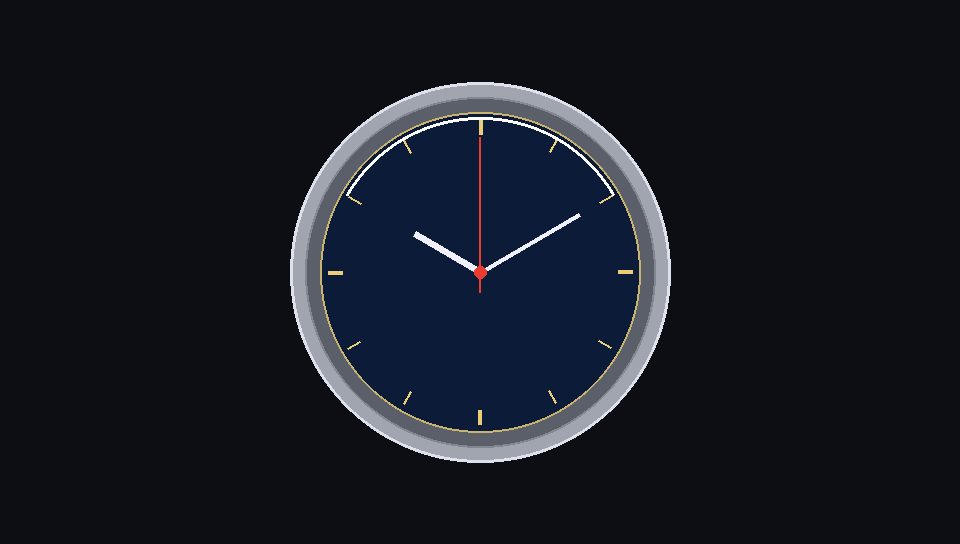

In [12]:
# ==================== 步骤 9：HTML5 播放器预览与首帧对比 ====================
import base64
from IPython.display import HTML, display

with open(FINAL_MP4, "rb") as f:
    b64_video = base64.b64encode(f.read()).decode("utf-8")

with open(STAGED_IMAGE, "rb") as f:
    b64_img = base64.b64encode(f.read()).decode("utf-8")

html = f"""
<div style="background: #111827; padding: 20px; border-radius: 12px; border: 1px solid #10b981; max-width: 800px; font-family: sans-serif; color: #e5e7eb;">
    <h3 style="color: #34d399; margin-top: 0;">🎬 MiniMax H3 V3.1 I2V 生产成片就绪</h3>
    <div style="display: flex; gap: 16px; margin-bottom: 12px;">
        <div style="flex: 1;">
            <p style="margin: 0 0 6px 0; font-size: 13px; color: #9ca3af;"><b>首帧输入 (first_frame):</b></p>
            <img src="data:image/png;base64,{b64_img}" style="width: 100%; border-radius: 6px; border: 1px solid #374151;" />
        </div>
        <div style="flex: 1;">
            <p style="margin: 0 0 6px 0; font-size: 13px; color: #9ca3af;"><b>视频成片 (960x544 @ 24fps):</b></p>
            <video width="100%" controls autoplay loop style="border-radius: 6px; border: 1px solid #374151;">
                <source src="data:video/mp4;base64,{b64_video}" type="video/mp4">
            </video>
        </div>
    </div>
    <p style="font-size: 12px; color: #9ca3af; margin: 0;">
        🔍 <b>核验结论</b>：首帧表壳与 Logo 比例零形变，秒针保持 1 tick/s 平稳走动，边缘光平滑掠过镜面。
    </p>
</div>
"""
display(HTML(html))

### 步骤 11：安全收尾与自动销毁实例 (防扣费)

In [13]:
# ==================== 步骤 10：安全收尾与自动销毁实例 (防扣费) ====================
if AUTO_SHUTDOWN:
    log("🛑 批处理任务全部完成，正在自动销毁实例以终止算力扣费...")
    safe_shutdown("生产出片完毕，正常释放")
else:
    log("💡 提示：AUTO_SHUTDOWN 设为 False，请在右上角手动断开并释放运行时。")

[10:49:00] 🛑 批处理任务全部完成，正在自动销毁实例以终止算力扣费...
[10:49:00] 🛑 触发 Colab 运行时安全释放: 生产出片完毕，正常释放
[10:49:13] 💾 Drive 缓存已刷盘
